In [2]:
# library import
from collections import defaultdict
from itertools import product
import matplotlib.pyplot as plt
import matplotlib as mpl
import warnings
import numpy as np
from scipy.spatial.distance import euclidean

# 폰트 설정
# 1. 맥 기본 한글 폰트 지정 (AppleGothic)
plt.rcParams['font.family'] = 'AppleGothic'

# 2. 마이너스 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

warnings.filterwarnings('ignore')

# 10 장 데이터 그룹화하기

## 10.1 중심성으로 클러스터 발견하기

##### Code 10-1 두 정규 분포를 사용하여 다트 좌표 모델링하기

In [3]:
np.random.seed(0)
mean = 0
variance = 2
x = np.random.normal(mean, variance**0.5)
y = np.random.normal(mean, variance**0.5)

print(f"임으로 던진 타티의 x 좌표는 {x:.2f} 입니다")
print(f"임으로 던진 타티의 y 좌표는 {y:.2f} 입니다")

임으로 던진 타티의 x 좌표는 2.49 입니다
임으로 던진 타티의 y 좌표는 0.57 입니다


##### Code 10-2 임의로 던져진 다트 시물레이션하기

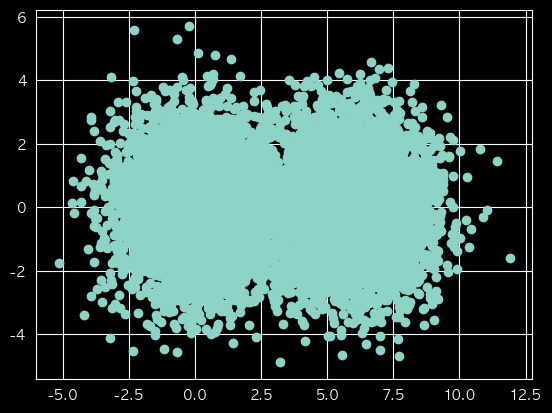

In [4]:
np.random.seed(1)
bulls_eye1 = [0,0]
bulls_eys2 = [6,0]
bulls_eyes = [bulls_eye1, bulls_eys2]
x_coordinates, y_coordinates = [] , []

for bulls_eye in bulls_eyes:
    for _ in range(5000):
        x = np.random.normal(bulls_eye[0], variance**0.5)
        y = np.random.normal(bulls_eye[1], variance**0.5)
        x_coordinates.append(x)
        y_coordinates.append(y)

plt.scatter(x_coordinates, y_coordinates)
plt.show()

##### Code 10-3 가장 가까운 과녁에 다트 활당하기

In [4]:
def nearest_bulls_eys(dart):
    distance = [euclidean(dart, bulls_e) for bulls_e in bulls_eyes]
    return np.argmin(distance)

darts = [[0,1],[6,1]]
for dart in darts:
    index = nearest_bulls_eys(dart)
    print(f"위치 {dart}의 다트는 {index}번째 과녁에 가장 가깝습니다")

위치 [0, 1]의 다트는 0번째 과녁에 가장 가깝습니다
위치 [6, 1]의 다트는 1번째 과녁에 가장 가깝습니다


##### Code 10-4 가장 가까운 과녁을 기준으로 다트 색칠하기

In [13]:
import pandas as pd
import numpy as np

# --------------------
# 1) 입력 로드
# --------------------
df = pd.read_csv("/Users/bestw/Desktop/ex/python_ex/PythonProject/Book_Study/실적_데이터_분석_With_파이썬/제 2 부 부번째 사례 탐구 : 온라인 광고 클릭의 유의성 평가하기/input_green_part.csv", encoding="utf-8-sig")

print(df.head())

COL_ITEM = "Item_Item"
COL_WEEK = "Time_Week"
COL_TYPE = "Type"
COL_QTY  = "Qty"
COL_LOT  = "Lot_Size"

KEEP_VAL = "Keep"   # keep 표시값 (Type 컬럼에 Keep/Down)

# 숫자형 변환
df[COL_WEEK] = pd.to_numeric(df[COL_WEEK], errors="coerce").astype("Int64")
df[COL_QTY]  = pd.to_numeric(df[COL_QTY],  errors="coerce").fillna(0).astype(int)
df[COL_LOT]  = pd.to_numeric(df[COL_LOT],  errors="coerce").fillna(0).astype(int)

# --------------------
# 2) 최초할당 / 잔량
# --------------------
df["Lot_alloc"] = np.where(df[COL_LOT] > 0, (df[COL_QTY] // df[COL_LOT]) * df[COL_LOT], 0)
df["rem"] = df[COL_QTY] - df["Lot_alloc"]

# 주차별 rem 합(문제지 표의 rem_week_cumsum)
df["rem_week_cumsum"] = df.groupby([COL_ITEM, COL_WEEK])["rem"].transform("sum")

# --------------------
# 3) 재할당 결과 컬럼 초기화
# --------------------
df["재_할당"] = 0
df["Keep_추가할당"] = 0
df["KeeP_우선순위"] = np.nan
df["재할당_잔량"] = 0  # 주차 종료 후 남아 다음주로 넘어갈 carry (keep 처리 후)

# 디버깅/검증용
df["keep_is_selected"] = False
df["keep_rank"] = np.nan
df["carry_in_week"] = 0
df["pool_in_week"] = 0
df["pool_after_realloc_week"] = 0
df["pool_after_keep_week"] = 0
df["rounds_week"] = 0

# --------------------
# 4) (item,week)->rows / item->weeks (df 내부 week만)
#    ⚠️ df 현재 행 순서가 "우선순위"라고 가정(중요)
# --------------------
idx_map = {(it, wk): g.index.to_numpy()
           for (it, wk), g in df.groupby([COL_ITEM, COL_WEEK], sort=False)}

weeks_map = (df.groupby(COL_ITEM)[COL_WEEK]
               .apply(lambda s: sorted([int(x) for x in s.dropna().unique().tolist()]))
               .to_dict())

# --------------------
# 5) 재할당 엔진
#    - 주차별 pool = carry + rem_sum
#    - 반복 라운드로 1 lot씩 배정(줄 곳 없을 때까지)
#    - pool 남고 keep 있으면: keep 우선순위(강제 전 absdiff) 최대인 keep 1개에 pool 전부 강제소진
#    - keep 없으면 pool을 다음주로 carry
# --------------------
for it, week_list in weeks_map.items():
    carry = 0

    for wk in week_list:
        rows = idx_map.get((it, wk))
        if rows is None or len(rows) == 0:
            continue

        rem_sum = int(df.loc[rows, "rem"].sum())
        pool = carry + rem_sum

        # 기록
        df.loc[rows, "carry_in_week"] = int(carry)
        df.loc[rows, "pool_in_week"] = int(pool)

        if pool <= 0:
            df.loc[rows, ["pool_after_realloc_week", "pool_after_keep_week", "rounds_week"]] = 0
            df.loc[rows, "재할당_잔량"] = 0
            carry = 0
            continue

        # ---- 반복 라운드(1 lot씩) ----
        rounds = 0
        while True:
            rounds += 1
            allocated_any = False

            for j in rows:
                lot = int(df.at[j, COL_LOT])
                if lot <= 0:
                    continue

                if pool >= lot:
                    df.at[j, "재_할당"] += lot
                    pool -= lot
                    allocated_any = True
                    if pool == 0:
                        break

            if pool == 0 or (not allocated_any):
                break

        df.loc[rows, "rounds_week"] = rounds
        df.loc[rows, "pool_after_realloc_week"] = int(pool)

        # ---- keep 강제소진 ----
        if pool > 0:
            keep_rows = [j for j in rows if str(df.at[j, COL_TYPE]) == KEEP_VAL]
            if keep_rows:
                # keep_추가할당 직전 기준 우선순위: abs(Qty - (Lot_alloc + 재_할당))
                base_before_keep = df.loc[keep_rows, "Lot_alloc"] + df.loc[keep_rows, "재_할당"]
                keep_priority = (df.loc[keep_rows, COL_QTY] - base_before_keep).abs()

                df.loc[keep_rows, "KeeP_우선순위"] = keep_priority.values
                df.loc[keep_rows, "keep_rank"] = keep_priority.rank(method="first", ascending=False).values

                j_keep = keep_priority.idxmax()
                df.at[j_keep, "keep_is_selected"] = True

                df.at[j_keep, "Keep_추가할당"] += int(pool)
                pool = 0

        # ---- 주차 종료: 남은 pool은 다음주 carry (keep 있으면 0) ----
        df.loc[rows, "pool_after_keep_week"] = int(pool)
        df.loc[rows, "재할당_잔량"] = int(pool)
        carry = pool

# --------------------
# 6) 최종수량
# --------------------
df["최종수량"] = df["Lot_alloc"] + df["재_할당"] + df["Keep_추가할당"]

# --------------------
# 7) 노란색 컬럼만 추출(답안지 형태)
# --------------------
df_yellow = df[[COL_ITEM, COL_WEEK, COL_TYPE,COL_QTY,COL_LOT,
               "Lot_alloc","rem","rem_week_cumsum",
               "재_할당","재할당_잔량","Keep_추가할당","최종수량","KeeP_우선순위"]].copy()


  Item_Item  Time_Week  Type   Qty  Lot_Size
0      AAAA     202607  Down   351        30
1      AAAA     202607  Down  2221        10
2      AAAA     202607  Down    98        46
3      AAAA     202609  Down    89        24
4      AAAA     202609  Down   200        29


In [14]:
df_yellow.to_clipboard()

In [1]:
import pandas as pd
import numpy as np

# --------------------
# 1) 입력 로드
# --------------------
df = pd.read_csv(
    "//Users/bestw/Desktop/ex/python_ex/PythonProject/Book_Study/실적_데이터_분석_With_파이썬/제 2 부 부번째 사례 탐구 : 온라인 광고 클릭의 유의성 평가하기/input_green_part_with_version.csv",
    encoding="utf-8-sig"
)

# ✅ 컬럼명 지정
COL_VER  = "version"      # <- 네 DF의 버전 컬럼명으로 바꿔 (예: "Version")
COL_ITEM = "Item_Item"
COL_WEEK = "Time_Week"
COL_TYPE = "Type"
COL_QTY  = "Qty"
COL_LOT  = "Lot_Size"

KEEP_VAL = "Keep"   # Type 컬럼에 Keep/Down

# --------------------
# 2) 숫자형 변환
# --------------------
df[COL_WEEK] = pd.to_numeric(df[COL_WEEK], errors="coerce").astype("Int64")
df[COL_QTY]  = pd.to_numeric(df[COL_QTY],  errors="coerce").fillna(0).astype(int)
df[COL_LOT]  = pd.to_numeric(df[COL_LOT],  errors="coerce").fillna(0).astype(int)

# --------------------
# 3) 최초할당 / 잔량
# --------------------
df["Lot_alloc"] = np.where(df[COL_LOT] > 0, (df[COL_QTY] // df[COL_LOT]) * df[COL_LOT], 0)
df["rem"] = df[COL_QTY] - df["Lot_alloc"]

# ✅ 버전 포함해서 주차별 rem 합
df["rem_week_cumsum"] = df.groupby([COL_VER, COL_ITEM, COL_WEEK])["rem"].transform("sum")

# --------------------
# 4) 재할당 결과 컬럼 초기화
# --------------------
df["재_할당"] = 0
df["Keep_추가할당"] = 0
df["KeeP_우선순위"] = np.nan
df["재할당_잔량"] = 0  # 주차 종료 후 남아 다음주로 넘어갈 carry (keep 처리 후)

# 디버깅/검증용
df["keep_is_selected"] = False
df["keep_rank"] = np.nan
df["carry_in_week"] = 0
df["pool_in_week"] = 0
df["pool_after_realloc_week"] = 0
df["pool_after_keep_week"] = 0
df["rounds_week"] = 0

# --------------------
# 5) idx_map / weeks_map  (✅ 버전 포함)
#    ⚠️ df 현재 행 순서가 "우선순위"라고 가정
# --------------------
idx_map = {(v, it, wk): g.index.to_numpy()
           for (v, it, wk), g in df.groupby([COL_VER, COL_ITEM, COL_WEEK], sort=False)}

weeks_map = (df.groupby([COL_VER, COL_ITEM])[COL_WEEK]
               .apply(lambda s: sorted([int(x) for x in s.dropna().unique().tolist()]))
               .to_dict())

# --------------------
# 6) 재할당 엔진
# --------------------
for (v, it), week_list in weeks_map.items():
    carry = 0

    for wk in week_list:
        rows = idx_map.get((v, it, wk))
        if rows is None or len(rows) == 0:
            continue

        rem_sum = int(df.loc[rows, "rem"].sum())
        pool = carry + rem_sum

        # 기록
        df.loc[rows, "carry_in_week"] = int(carry)
        df.loc[rows, "pool_in_week"] = int(pool)

        if pool <= 0:
            df.loc[rows, ["pool_after_realloc_week", "pool_after_keep_week", "rounds_week"]] = 0
            df.loc[rows, "재할당_잔량"] = 0
            carry = 0
            continue

        # ---- 반복 라운드(1 lot씩) ----
        rounds = 0
        while True:
            rounds += 1
            allocated_any = False

            for j in rows:
                lot = int(df.at[j, COL_LOT])
                if lot <= 0:
                    continue

                if pool >= lot:
                    df.at[j, "재_할당"] += lot
                    pool -= lot
                    allocated_any = True
                    if pool == 0:
                        break

            if pool == 0 or (not allocated_any):
                break

        df.loc[rows, "rounds_week"] = rounds
        df.loc[rows, "pool_after_realloc_week"] = int(pool)

        # ---- keep 강제소진 ----
        if pool > 0:
            keep_rows = [j for j in rows if str(df.at[j, COL_TYPE]) == KEEP_VAL]
            if keep_rows:
                base_before_keep = df.loc[keep_rows, "Lot_alloc"] + df.loc[keep_rows, "재_할당"]
                keep_priority = (df.loc[keep_rows, COL_QTY] - base_before_keep).abs()

                df.loc[keep_rows, "KeeP_우선순위"] = keep_priority.values
                df.loc[keep_rows, "keep_rank"] = keep_priority.rank(method="first", ascending=False).values

                j_keep = keep_priority.idxmax()
                df.at[j_keep, "keep_is_selected"] = True

                df.at[j_keep, "Keep_추가할당"] += int(pool)
                pool = 0

        # ---- 주차 종료: 남은 pool은 다음주 carry (keep 있으면 0) ----
        df.loc[rows, "pool_after_keep_week"] = int(pool)
        df.loc[rows, "재할당_잔량"] = int(pool)
        carry = pool

# --------------------
# 7) 최종수량
# --------------------
df["최종수량"] = df["Lot_alloc"] + df["재_할당"] + df["Keep_추가할당"]

# --------------------
# 8) 노란색 컬럼 추출(답안지 형태)
# --------------------
df_yellow = df[[COL_VER, COL_ITEM, COL_WEEK, COL_TYPE, COL_QTY, COL_LOT,
               "Lot_alloc", "rem", "rem_week_cumsum",
               "재_할당", "재할당_잔량", "Keep_추가할당", "최종수량", "KeeP_우선순위"]].copy()


In [16]:
df_yellow.to_clipboard()

In [28]:
import pandas as pd
import numpy as np

def to_yyyymm_int_safe(
    s: pd.Series,
    treat_yyyyww_as_iso_week: bool = True,
    epoch_year_min: int = 1970,
    epoch_year_max: int = 2100,
) -> pd.Series:

    ss = s.astype("string").str.strip()

    # 0) float로 읽혀 "20180101.0" 같은 꼴 제거
    ss = ss.str.replace(r"\.0+$", "", regex=True)

    dt = pd.Series(pd.NaT, index=ss.index, dtype="datetime64[ns]")

    m_valid = ss.notna() & (ss != "") & (ss.str.lower() != "not_a_date")

    # A) 2018.8.15 같은 점(.) 날짜 (월/일 1~2자리)
    m_dot = m_valid & ss.str.match(r"^\d{4}\.\d{1,2}\.\d{1,2}$", na=False)
    if m_dot.any():
        dt.loc[m_dot] = pd.to_datetime(ss.loc[m_dot], format="%Y.%m.%d", errors="coerce")

    m_left = dt.isna() & m_valid

    # B) 숫자/과학표기 -> float로 파싱(벡터)
    num = pd.to_numeric(ss.where(m_left), errors="coerce")

    # ---- epoch(ms) 후보: 대략 1970~2100 범위만 인정 ----
    # ms로 변환했을 때 연도 범위를 만족하는지로 필터링
    m_ms_candidate = m_left & num.between(1e11, 1e14)  # 너무 넓은 값은 일단 제외(안전장치)
    if m_ms_candidate.any():
        ms_int = num.loc[m_ms_candidate].round().astype("Int64")
        dt_ms = pd.to_datetime(ms_int, unit="ms", errors="coerce")
        # 연도 범위 필터
        ok = dt_ms.dt.year.between(epoch_year_min, epoch_year_max)
        dt.loc[dt_ms.index[ok.fillna(False)]] = dt_ms.loc[ok.fillna(False)]

    m_left = dt.isna() & m_valid
    num2 = pd.to_numeric(ss.where(m_left), errors="coerce")

    # ---- epoch(sec) 후보: 1970~2100 범위만 인정 ----
    m_s_candidate = m_left & num2.between(1e8, 1e11)  # 1e9 근처가 정상, 약간 여유
    if m_s_candidate.any():
        s_int = num2.loc[m_s_candidate].round().astype("Int64")
        dt_s = pd.to_datetime(s_int, unit="s", errors="coerce")
        ok = dt_s.dt.year.between(epoch_year_min, epoch_year_max)
        dt.loc[dt_s.index[ok.fillna(False)]] = dt_s.loc[ok.fillna(False)]

    m_left = dt.isna() & m_valid

    # C) digits 길이 기반(YYYYMMDD/14자리/6자리)
    digits = ss.where(m_left).str.replace(r"\D+", "", regex=True)
    dlen = digits.str.len()

    # YYYYMMDD
    m_8 = m_left & dlen.eq(8)
    if m_8.any():
        dt.loc[m_8] = pd.to_datetime(digits.loc[m_8], format="%Y%m%d", errors="coerce")

    m_left = dt.isna() & m_valid
    digits = ss.where(m_left).str.replace(r"\D+", "", regex=True)
    dlen = digits.str.len()

    # YYYYMMDDHHMMSS
    m_14 = m_left & dlen.eq(14)
    if m_14.any():
        dt.loc[m_14] = pd.to_datetime(digits.loc[m_14], format="%Y%m%d%H%M%S", errors="coerce")

    m_left = dt.isna() & m_valid
    digits = ss.where(m_left).str.replace(r"\D+", "", regex=True)
    dlen = digits.str.len()

    # 6자리: YYYYMM 또는 YYYYWW
    m_6 = m_left & dlen.eq(6)
    if m_6.any():
        if treat_yyyyww_as_iso_week:
            wk = pd.to_numeric(digits.loc[m_6].str[-2:], errors="coerce")
            if wk.between(1, 53).mean() >= 0.80:
                y = digits.loc[m_6].str[:4]
                w = digits.loc[m_6].str[4:6]
                iso = y + "-W" + w + "-1"
                dt.loc[m_6] = pd.to_datetime(iso, format="%G-W%V-%u", errors="coerce")
            else:
                dt.loc[m_6] = pd.to_datetime(digits.loc[m_6] + "01", format="%Y%m%d", errors="coerce")
        else:
            dt.loc[m_6] = pd.to_datetime(digits.loc[m_6] + "01", format="%Y%m%d", errors="coerce")

    m_left = dt.isna() & m_valid

    # D) 미국식 AM/PM (format 고정)
    m_ampm = m_left & ss.str.contains(r"\bAM\b|\bPM\b", case=False, regex=True, na=False)
    if m_ampm.any():
        dt.loc[m_ampm] = pd.to_datetime(ss.loc[m_ampm], format="%m/%d/%Y %I:%M %p", errors="coerce")
        m_ampm2 = m_ampm & dt.isna()
        if m_ampm2.any():
            dt.loc[m_ampm2] = pd.to_datetime(ss.loc[m_ampm2], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

    m_left = dt.isna() & m_valid

    # E) 마지막 fallback
    if m_left.any():
        dt.loc[m_left] = pd.to_datetime(ss.loc[m_left], errors="coerce", cache=True)

    # 결과: YYYYMM 정수
    yyyymm = dt.dt.year * 100 + dt.dt.month
    return yyyymm.astype("Int64")


In [29]:
import time
df = pd.read_csv('/Users/bestw/Desktop/ex/python_ex/PythonProject/Book_Study/실적_데이터_분석_With_파이썬/제 2 부 부번째 사례 탐구 : 온라인 광고 클릭의 유의성 평가하기/date_mixed_onecol_5000.csv', encoding="utf-8-sig")

t0 = time.time()
df["yyyymm_calc"] = to_yyyymm_int_safe(df["raw_date"], treat_yyyyww_as_iso_week=True)
t1 = time.time()

df.to_clipboard(index=False)

In [45]:
import pandas as pd
import numpy as np

def to_yyyymm_int(s: pd.Series) -> pd.Series:
    x = s.astype("string")

    # 보이지 않는 공백(NBSP) + 중복 공백 정리
    x = (x.str.replace("\u00A0", " ", regex=False)
           .str.replace(r"\s+", " ", regex=True)
           .str.strip())

    y = pd.Series(pd.NA, index=x.index, dtype="Int64")
    m = pd.Series(pd.NA, index=x.index, dtype="Int64")

    # 1) 연도가 앞에 오는 케이스: 2025-09-12, 2025.8.1 ..., 2025/09/01 ...
    ym = x.str.extract(r"^\s*(?P<y>\d{4})\D+(?P<m>\d{1,2})")
    y1 = pd.to_numeric(ym["y"], errors="coerce").astype("Int64")
    m1 = pd.to_numeric(ym["m"], errors="coerce").astype("Int64")

    ok1 = y1.between(1900, 2199) & m1.between(1, 12)
    y.loc[ok1] = y1.loc[ok1]
    m.loc[ok1] = m1.loc[ok1]

    # 2) 미국식(MM/DD/YYYY ...) 케이스: 06/03/2017 17:30:00, 6/3/2017 ...
    us = x.str.extract(r"^\s*(?P<m>\d{1,2})\D+(?P<d>\d{1,2})\D+(?P<y>\d{4})")
    y2 = pd.to_numeric(us["y"], errors="coerce").astype("Int64")
    m2 = pd.to_numeric(us["m"], errors="coerce").astype("Int64")

    ok2 = y.isna() & y2.between(1900, 2199) & m2.between(1, 12)
    y.loc[ok2] = y2.loc[ok2]
    m.loc[ok2] = m2.loc[ok2]

    # 3) 숫자만 있는 케이스(YYYYMMDD, YYYYMMDDHHMMSS, YYYYMMDD.0 등)
    digits = x.str.replace(r"\D+", "", regex=True)
    y3 = pd.to_numeric(digits.str.slice(0, 4), errors="coerce")
    m3 = pd.to_numeric(digits.str.slice(4, 6), errors="coerce")
    ok3 = y.isna() & y3.between(1900, 2199) & m3.between(1, 12)
    y.loc[ok3] = y3.loc[ok3].astype("Int64")
    m.loc[ok3] = m3.loc[ok3].astype("Int64")

    return (y * 100 + m).astype("Int64")


In [46]:
test = pd.Series([
    "06/03/2017 17:30:00",
    "2025.8.1  12:00:00 AM",
    "2025-09-01 00:00:00",
    "2025-09-12",
    "2026-01-05  12:00:00 PM",
    "06/03/2017 17:30:00 PM",
])

print(to_yyyymm_int(test).tolist())
# 기대: [201706, 202508, 202509, 202509, 202601, 201706]


[201706, 202508, 202509, 202509, 202601, 201706]


In [47]:
import pandas as pd

def to_yyyymm_int(s: pd.Series) -> pd.Series:
    x = (s.astype("string")
           .str.replace("\u00A0", " ", regex=False)
           .str.replace(r"\s+", " ", regex=True)
           .str.strip())

    # (1) 연도-월이 앞(YYYY?MM...) : 2025-09..., 2025.8..., 2025/09...
    a = x.str.extract(r"^(?P<y>\d{4})\D+(?P<m>\d{1,2})")
    y1 = pd.to_numeric(a["y"], errors="coerce")
    m1 = pd.to_numeric(a["m"], errors="coerce")

    # (2) 미국식(MM/DD/YYYY...) : 06/03/2017 ...
    b = x.str.extract(r"^(?P<m>\d{1,2})\D+\d{1,2}\D+(?P<y>\d{4})")
    y2 = pd.to_numeric(b["y"], errors="coerce")
    m2 = pd.to_numeric(b["m"], errors="coerce")

    # (3) 숫자만(YYYYMMDD/14자리/..): 앞 6자리에서 연/월
    d = x.str.replace(r"\D+", "", regex=True)
    y3 = pd.to_numeric(d.str.slice(0, 4), errors="coerce")
    m3 = pd.to_numeric(d.str.slice(4, 6), errors="coerce")

    # 유효 월만 남기고(1~12) 우선순위: (1) -> (2) -> (3)
    def valid(y, m):
        ok = y.between(1900, 2199) & m.between(1, 12)
        return y.where(ok), m.where(ok)

    y1, m1 = valid(y1, m1)
    y2, m2 = valid(y2, m2)
    y3, m3 = valid(y3, m3)

    y = y1.combine_first(y2).combine_first(y3)
    m = m1.combine_first(m2).combine_first(m3)

    return (y * 100 + m).astype("Int64")


In [48]:
print(to_yyyymm_int(test).tolist())

[201706, 202508, 202509, 202509, 202601, 201706]
